In [ ]:
!pip uninstall -y gym
!pip install gymnasium

Found existing installation: gym 0.25.2
Uninstalling gym-0.25.2:
  Successfully uninstalled gym-0.25.2


In [ ]:
import numpy as np
import gymnasium as gym # Changed import to gymnasium
import matplotlib.pyplot as plt

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
env = gym.make("FrozenLake-v1", is_slippery=False)


In [ ]:
# Dataset Explanation:
# FrozenLake-v1 is a 4x4 grid environment provided by OpenAI Gym.
# States: 16 discrete states (0 to 15), one for each grid cell.
# Actions: 4 (0=Left, 1=Down, 2=Right, 3=Up)
# Goal: Reach the goal (G) from the start (S) without falling into holes (H).
# State-Action Space Size
n_states = env.observation_space.n
n_actions = env.action_space.n

In [ ]:
Q = np.zeros((n_states, n_actions))
# Step 5: Define Hyperparameters
alpha = 0.8 # Learning rate
gamma = 0.95 # Discount factor
epsilon = 0.1 # Exploration rate
episodes = 1000 # Number of training episodes
max_steps = 100 # Max steps per episode
# Optional Enhancement: Tracking rewards
rewards_per_episode = []

In [ ]:
for episode in range(episodes):
  state = env.reset()
  if isinstance(state, tuple): # For newer gym versions
    state = state[0]
  total_reward = 0
  done = False
  for step in range(max_steps):
    # Epsilon-greedy action selection
    if np.random.uniform(0, 1) < epsilon:
      action = env.action_space.sample()
    else:
      action = np.argmax(Q[state, :])
    # Take action
    new_state, reward, done, *_ = env.step(action)
    if isinstance(new_state, tuple):
      new_state = new_state[0]
    # Q-Learning update
    Q[state, action] += alpha * (reward + gamma * np.max(Q[new_state, :]) - Q[state,
  action])
    state = new_state
    total_reward += reward
    if done:
      break
  rewards_per_episode.append(total_reward)

In [ ]:
print("Final Q-Table:")
print(np.round(Q, 2))

Final Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]



 Learned Policy Grid:
← ← ← ←
← ← ← ←
← ← ← ←
← ← ← ←


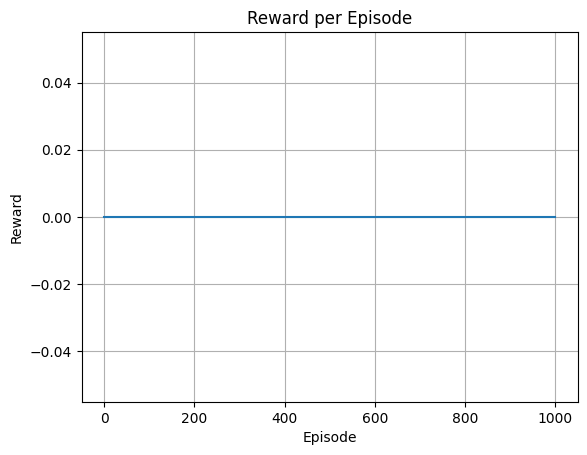

In [ ]:
actions = ["←", "↓", "→", "↑"]
policy = [actions[np.argmax(row)] for row in Q]
policy = np.array(policy).reshape((4, 4))
print("\n Learned Policy Grid:")
for row in policy:
 print(" ".join(row))
# Optional: Plot Learning Progress
plt.plot(range(episodes), rewards_per_episode)
plt.title("Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.grid(True)
plt.show()
